In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

# print(os.getcwd())
# print(os.path.abspath(base_path))


pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", None)
pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", None)

In [2]:
ls

Ablation Max Analyser.ipynb    mmlu_test_eval_service_3_300/
mmlu_test_eval_service_10_300/ mmlu_test_eval_service_5_300/
mmlu_test_eval_service_12_300/ mmlu_test_eval_service_8_300/
mmlu_test_eval_service_14_300/


In [3]:
base_path = "."

folders = {

    3: "mmlu_test_eval_service_3_300",
    5: "mmlu_test_eval_service_5_300",
    8: "mmlu_test_eval_service_8_300",
    10: "mmlu_test_eval_service_10_300",
    12:"mmlu_test_eval_service_12_300",
    14:"mmlu_test_eval_service_14_300"

}

In [4]:
data = {}

for k, folder_name in folders.items():

    folder_path = os.path.join(base_path, folder_name)
#     print(folder_path)

    data[k] = []

    for file_name in os.listdir(folder_path):

        if not file_name.endswith(".json"):
            continue

        if "_efficiency" in file_name:
            continue

        file_path = os.path.join(folder_path, file_name)
#         print(file_path)

        with open(file_path, "r") as f:
            rows = json.load(f)
#             print(rows)

        for row in rows:
            row = row.copy()
            row["source_file"] = file_name
            data[k].append(row)

    print(f"K={k}: loaded {len(data[k])} rows")

K=3: loaded 1800 rows
K=5: loaded 2400 rows
K=8: loaded 3300 rows
K=10: loaded 3900 rows
K=12: loaded 4500 rows
K=14: loaded 5100 rows


In [5]:
df_k3 = pd.DataFrame(data[3])
df_k5 = pd.DataFrame(data[5])
df_k8 = pd.DataFrame(data[8])
df_k10 = pd.DataFrame(data[10])
df_k12 = pd.DataFrame(data[12])
df_k14 = pd.DataFrame(data[14])


print("K=3:", df_k3.shape)
print("K=5:", df_k5.shape)
print("K=8:", df_k8.shape)
print("K=10:", df_k10.shape)
print("K=12:", df_k12.shape)
print("K=14:", df_k14.shape)


K=3: (1800, 31)
K=5: (2400, 33)
K=8: (3300, 36)
K=10: (3900, 38)
K=12: (4500, 40)
K=14: (5100, 42)


In [6]:
# df_k3.columns.tolist()# df_k3.columns

### combined df

In [7]:
df_combined = pd.concat([df_k3, df_k5, df_k8, df_k10, df_k12, df_k14], ignore_index=True)

print(df_combined.shape)
print(df_combined["total_service_count"].value_counts())
# df_combined.columns

(21000, 42)
14    5100
12    4500
10    3900
8     3300
5     2400
3     1800
Name: total_service_count, dtype: int64


In [9]:
df_combined.head()

,routing_method,query,raw_response,predicted_label,top_candidate,model_name,latency_ms,max_score,median_score,abstract_algebra_score,anatomy_score,astronomy_score,apply_threshold,gate,gap,gap_cutoff,gap_passed,margin,margin_cutoff,margin_passed,zscore,gate_value,gate_cutoff,gate_passed,expected_service,is_correct,error,energy_kwh,co2_kg,total_service_count,source_file,business_ethics_score,college_computer_science_score,high_school_chemistry_score,high_school_geography_score,jurisprudence_score,world_religions_score,formal_logic_score,marketing_score,sociology_score,high_school_psychology_score,prehistory_score
0,cross-encoder,"Statement 1 | If a group has an element of order 10, then it has elements of orders 1, 2, and 5. Statement 2 | If a group has an element of order 2 and an element of order 3, then it has an element of order 6.",None,abstract_algebra,abstract_algebra,Qwen/Qwen3-Reranker-4B,257.162794,3.8125,-11.8750,3.8125,-11.8750,-12.6250,True,max,15.6875,None,None,15.6875,None,None,1.413059,3.8125,-9.07065,True,abstract_algebra,True,None,0.000361,0.000198,3,cross-encoder_Qwen-Qwen3-Reranker-4B.json,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,cross-encoder,"Statement 1 | If G, H and K are groups of order 4, at least two of them are isomorphic. Statement 2 | If Z_r + Z_s is isomorphic to a subgroup Z_m + Z_n, then r divides m and s divides n.",None,abstract_algebra,abstract_algebra,Qwen/Qwen3-Reranker-4B,52.743827,6.4375,-11.8125,6.4375,-11.8125,-12.8125,True,max,18.2500,None,None,18.2500,None,None,1.412707,6.4375,-9.07065,True,abstract_algebra,True,None,0.000007,0.000004,3,cross-encoder_Qwen-Qwen3-Reranker-4B.json,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,cross-encoder,"(Z,*) is a group with a*b = a+b+1 for all a, b in Z. The inverse of a is",None,abstract_algebra,abstract_algebra,Qwen/Qwen3-Reranker-4B,56.482110,-3.6875,-11.8125,-3.6875,-11.8750,-11.8125,True,max,8.1250,None,None,8.1250,None,None,1.414182,-3.6875,-9.07065,True,abstract_algebra,True,None,0.000009,0.000005,3,cross-encoder_Qwen-Qwen3-Reranker-4B.json,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,cross-encoder,"Statement 1 | For any two groups G and G', there exists a homomorphism of G into G'. Statement 2 | Every homomorphism is a one-to-one map.",None,abstract_algebra,abstract_algebra,Qwen/Qwen3-Reranker-4B,50.634675,4.1875,-11.6250,4.1875,-11.6250,-12.6875,True,max,15.8125,None,None,15.8125,None,None,1.411978,4.1875,-9.07065,True,abstract_algebra,True,None,0.000009,0.000005,3,cross-encoder_Qwen-Qwen3-Reranker-4B.json,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,cross-encoder,"Let A and B be sets, f: A -> B and g: B -> A be functions such that for all a \in A, g(f(a)) = a. Statement 1 | The function f must necessarily be injective. Statement 2 | The function f must necessarily be surjective.",None,abstract_algebra,abstract_algebra,Qwen/Qwen3-Reranker-4B,54.554235,-3.6250,-10.1250,-3.6250,-10.1250,-10.7500,True,max,6.5000,None,None,6.5000,None,None,1.409771,-3.6250,-9.07065,True,abstract_algebra,True,None,0.000014,0.000008,3,cross-encoder_Qwen-Qwen3-Reranker-4B.json,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Can Retrieval models route?

In [8]:
df_acc = df_combined.copy()     

acc_table = df_acc.pivot_table(
    index=["routing_method", "model_name"],
    columns="total_service_count",
    values="is_correct",
    aggfunc="mean",
).mul(100).round(2)

acc_table = acc_table.sort_values(["routing_method", 14], ascending=[True, False])
# acc_table.to_latex()
acc_table

,total_service_count,3,5,8,10,12,14
routing_method,model_name,,,,,,
bi-encoder,BAAI/bge-large-en-v1.5,95.5,93.50,87.27,84.85,78.87,75.47
colbert,lightonai/Reason-ModernColBERT,57.0,44.00,38.36,35.54,31.47,30.06
cross-encoder,Qwen/Qwen3-Reranker-4B,91.5,88.25,80.18,74.85,68.40,63.00


## How well are specialist and off-topic queries routed?

In [16]:
keys = ["routing_method", "model_name", "total_service_count"]
is_general = df_acc["expected_service"] == "general"

acc  = df_acc.groupby(keys)["is_correct"].mean() * 100
spec = df_acc[~is_general].groupby(keys)["is_correct"].mean() * 100
gen  = df_acc[is_general].groupby(keys)["is_correct"].mean() * 100

df_recall = pd.DataFrame({"Acc.": acc, "Spec.": spec, "Gen.": gen}).round(2)
df_recall

k3_recall  = df_recall.xs(3,  level="total_service_count")
k9_recall = df_recall.xs(9, level="total_service_count")

recall_k3_k9 = pd.concat([k3_recall, k9_recall], axis=1, keys=["K=3", "K=9"])
recall_k3_k9

K=3                 \
                                                        Acc.  Spec.    Gen.   
routing_method model_name                                                     
bi-encoder     BAAI/bge-large-en-v1.5                  74.17  47.78   90.00   
               Qwen/Qwen3-Embedding-0.6B               56.88  34.44   70.33   
               Qwen/Qwen3-Embedding-4B                 33.75  42.22   28.67   
               Qwen/Qwen3-Embedding-8B                 74.38  47.22   90.67   
               sentence-transformers/all-MiniLM-L6-v2  72.08  40.00   91.33   
colbert        LiquidAI/LFM2-ColBERT-350M              81.25  58.89   94.67   
               colbert-ir/colbertv2.0                  68.33  31.11   90.67   
               lightonai/Reason-ModernColBERT          76.67  52.22   91.33   
               mixedbread-ai/mxbai-colbert-large-v1    63.12  25.00   86.00   
cross-encoder  BAAI/bge-reranker-v2-m3                 77.50  42.22   98.67   
               Qwen/Qwen3-Reranker-0.6B                58.13  47.78   64.33   
               Qwen/Qwen3-Reranker-4B                  74.58  63.33   81.33   
               Qwen/Qwen3-Reranker-8B                  84.38  68.33   94.00   
               mixedbread-ai/mxbai-rerank-large-v2     84.17  65.56   95.33   
llm            llama3.1:8b                             80.83  76.67   83.33   
               phi4:14b                                82.50  55.56   98.67   
               qwen2.5:14b                             91.46  77.78   99.67   
               qwen2.5:32b                             81.04  49.44  100.00   
               qwen2.5:7b                              77.29  39.44  100.00   

                                                         K=9                 
                                                        Acc.  Spec.    Gen.  
routing_method model_name                                                    
bi-encoder     BAAI/bge-large-en-v1.5                  65.71  48.33   97.00  
               Qwen/Qwen3-Embedding-0.6B               58.33  38.70   93.67  
               Qwen/Qwen3-Embedding-4B                 64.05  50.74   88.00  
               Qwen/Qwen3-Embedding-8B                 60.24  39.26   98.00  
               sentence-transformers/all-MiniLM-L6-v2  62.38  46.30   91.33  
colbert        LiquidAI/LFM2-ColBERT-350M              66.43  55.19   86.67  
               colbert-ir/colbertv2.0                  47.38  23.89   89.67  
               lightonai/Reason-ModernColBERT          69.52  54.26   97.00  
               mixedbread-ai/mxbai-colbert-large-v1    47.26  22.96   91.00  
cross-encoder  BAAI/bge-reranker-v2-m3                 56.31  33.89   96.67  
               Qwen/Qwen3-Reranker-0.6B                64.05  47.04   94.67  
               Qwen/Qwen3-Reranker-4B                  75.24  63.15   97.00  
               Qwen/Qwen3-Reranker-8B                  79.64  71.11   95.00  
               mixedbread-ai/mxbai-rerank-large-v2     75.48  65.74   93.00  
llm            llama3.1:8b                             74.76  68.15   86.67  
               phi4:14b                                77.98  66.11   99.33  
               qwen2.5:14b                             80.12  69.81   98.67  
               qwen2.5:32b                             73.33  58.52  100.00  
               qwen2.5:7b                              62.38  41.48  100.00

In [28]:
import pandas as pd

keys = ["routing_method", "model_name", "total_service_count"]
is_general = df_acc["expected_service"] == "general"

df = pd.DataFrame({
    "Acc.":  df_acc.groupby(keys)["is_correct"].mean() * 100,
    "Spec.": df_acc[~is_general].groupby(keys)["is_correct"].mean() * 100,
    "Gen.":  df_acc[is_general].groupby(keys)["is_correct"].mean() * 100,
})

chosen = [
    "BAAI/bge-large-en-v1.5", "Qwen/Qwen3-Embedding-8B",
    "LiquidAI/LFM2-ColBERT-350M", "lightonai/Reason-ModernColBERT",
    "Qwen/Qwen3-Reranker-8B", "Qwen/Qwen3-Reranker-4B", "mixedbread-ai/mxbai-rerank-large-v2",
    "qwen2.5:14b", "phi4:14b", "qwen2.5:32b", "llama3.1:8b",
]
strong = ["Qwen/Qwen3-Reranker-8B", "mixedbread-ai/mxbai-rerank-large-v2"]
ks, cols = [3, 5, 7, 9], ["Acc.", "Spec.", "Gen."]

wide = df.droplevel("routing_method").unstack("total_service_count").swaplevel(axis=1)
wide = wide[[(k, c) for k in ks for c in cols]].loc[chosen]

display(wide.style.format("{:.2f}").apply(
    lambda r: ["font-weight: bold" if r.name in strong else ""] * len(r), axis=1))

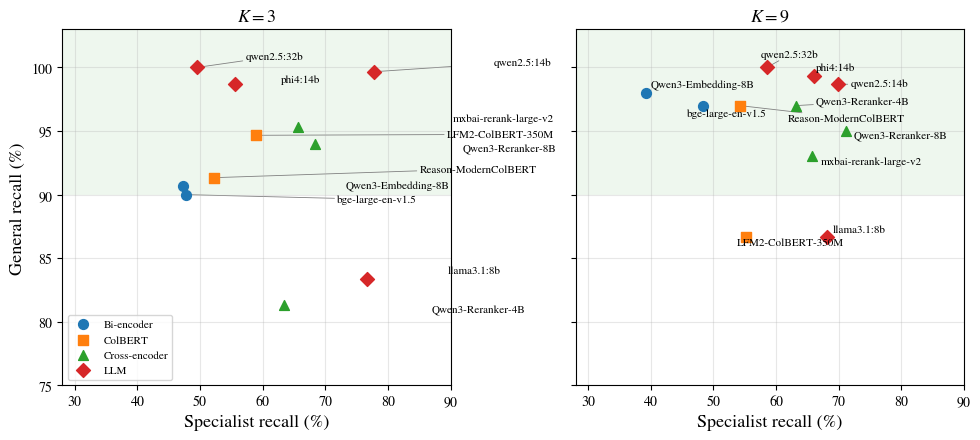

In [33]:
from matplotlib.patches import Rectangle
from adjustText import adjust_text
import pandas as pd

plt.rcParams.update({"font.family": "STIXGeneral", "mathtext.fontset": "stix", "pdf.fonttype": 42,
                     "font.size": 13, "axes.titlesize": 13, "axes.labelsize": 13,
                     "xtick.labelsize": 10, "ytick.labelsize": 10, "legend.fontsize": 10})

style = {"bi-encoder": ("o", "tab:blue", "Bi-encoder"),
         "colbert": ("s", "tab:orange", "ColBERT"),
         "cross-encoder": ("^", "tab:green", "Cross-encoder"),
         "llm": ("D", "tab:red", "LLM")}

both = pd.concat([df.xs(3, level="total_service_count"),
                  df.xs(9, level="total_service_count")], axis=1, keys=["K=3", "K=9"])
both = both[both.index.get_level_values("model_name").isin(chosen)]

fig, axes = plt.subplots(1, 2, figsize=(10, 4.6), sharex=True, sharey=True)
for ax, k in zip(axes, [3, 9]):
    spec, gen = both[(f"K={k}", "Spec.")], both[(f"K={k}", "Gen.")]

    ax.add_patch(Rectangle((0, 90), 200, 20, color="tab:green", alpha=0.08, lw=0, zorder=0))

    for fam, (marker, color, name) in style.items():
        ax.scatter(spec.loc[fam], gen.loc[fam], marker=marker, color=color,
                   s=50, label=name, zorder=3)

    texts = [ax.text(spec[(fam, router)], gen[(fam, router)], router.split("/")[-1], fontsize=8)
             for fam, router in both.index]
    adjust_text(texts, x=spec.values, y=gen.values, ax=ax,
                arrowprops=dict(arrowstyle="-", lw=0.6, color="gray"))

    ax.set_title(f"$K={k}$")
    ax.set_xlabel("Specialist recall (%)")
    ax.set_xlim(28, 90)
    ax.set_ylim(75, 103)
    ax.grid(alpha=0.3)

axes[0].set_ylabel("General recall (%)")
axes[0].legend(loc="lower left", fontsize=8)
plt.tight_layout()
plt.savefig("medmcqa_recall_scatter.pdf")
plt.show()

## What does routing cost?

In [31]:
df_cost = df_combined.copy() 

In [32]:
# convert energy to mWh

df_cost["energy_mwh"] = df_cost["energy_kwh"] * 1_000_000


lat = (df_cost[df_cost["total_service_count"].isin([3, 14])]
       .groupby(["routing_method", "model_name", "total_service_count"])["latency_ms"]
       .median()
       .unstack("total_service_count"))
lat

total_service_count                                             3   \
routing_method model_name                                            
bi-encoder     BAAI/bge-large-en-v1.5                    14.259158   
               Qwen/Qwen3-Embedding-0.6B                 29.218834   
               Qwen/Qwen3-Embedding-4B                   38.642646   
               Qwen/Qwen3-Embedding-8B                   36.850527   
               sentence-transformers/all-MiniLM-L6-v2     4.807793   
colbert        LiquidAI/LFM2-ColBERT-350M                14.567956   
               colbert-ir/colbertv2.0                     9.385190   
               lightonai/Reason-ModernColBERT            15.824815   
               mixedbread-ai/mxbai-colbert-large-v1      16.049722   
cross-encoder  BAAI/bge-reranker-v2-m3                   25.143710   
               Qwen/Qwen3-Reranker-0.6B                  32.815672   
               Qwen/Qwen3-Reranker-4B                    44.744222   
               Qwen/Qwen3-Reranker-8B                    59.796803   
               mixedbread-ai/mxbai-rerank-large-v2       28.059963   
llm            llama3.1:8b                               42.584796   
               phi4:14b                                  67.228752   
               qwen2.5:14b                               72.142917   
               qwen2.5:32b                              132.134290   
               qwen2.5:7b                                44.808680   
               qwen3:32b                               5197.933255   

total_service_count                                             14  
routing_method model_name                                           
bi-encoder     BAAI/bge-large-en-v1.5                    14.377516  
               Qwen/Qwen3-Embedding-0.6B                 29.329899  
               Qwen/Qwen3-Embedding-4B                   37.577083  
               Qwen/Qwen3-Embedding-8B                   37.433325  
               sentence-transformers/all-MiniLM-L6-v2     4.935172  
colbert        LiquidAI/LFM2-ColBERT-350M                14.769075  
               colbert-ir/colbertv2.0                     9.559965  
               lightonai/Reason-ModernColBERT            16.296974  
               mixedbread-ai/mxbai-colbert-large-v1      16.345339  
cross-encoder  BAAI/bge-reranker-v2-m3                   75.324194  
               Qwen/Qwen3-Reranker-0.6B                  40.959907  
               Qwen/Qwen3-Reranker-4B                   142.352894  
               Qwen/Qwen3-Reranker-8B                   219.215223  
               mixedbread-ai/mxbai-rerank-large-v2       59.532795  
llm            llama3.1:8b                               54.324337  
               phi4:14b                                  78.751384  
               qwen2.5:14b                               93.835631  
               qwen2.5:32b                              150.947071  
               qwen2.5:7b                                51.520173  
               qwen3:32b                               6512.118548

In [33]:
k14_cost = df_cost[df_cost["total_service_count"] == 14]
group_k14_cost = k14_cost.groupby(["routing_method", "model_name"])

acc_cost = group_k14_cost["is_correct"].mean() * 100
energy_cost = group_k14_cost["energy_mwh"].mean()

In [34]:
table_cost = pd.DataFrame({
    "Acc. K=14 (%)": acc_cost,
    "Lat. K=3 (ms)": lat[3],
    "Lat. K=14 (ms)": lat[14],
    "Energy K=14 (mWh)": energy_cost,
}).round(2)

table_cost

Acc. K=14 (%)  \
routing_method model_name                                              
bi-encoder     BAAI/bge-large-en-v1.5                          69.00   
               Qwen/Qwen3-Embedding-0.6B                       62.18   
               Qwen/Qwen3-Embedding-4B                         54.76   
               Qwen/Qwen3-Embedding-8B                         63.06   
               sentence-transformers/all-MiniLM-L6-v2          66.82   
colbert        LiquidAI/LFM2-ColBERT-350M                      69.59   
               colbert-ir/colbertv2.0                          50.47   
               lightonai/Reason-ModernColBERT                  72.35   
               mixedbread-ai/mxbai-colbert-large-v1            56.94   
cross-encoder  BAAI/bge-reranker-v2-m3                         59.71   
               Qwen/Qwen3-Reranker-0.6B                        70.35   
               Qwen/Qwen3-Reranker-4B                          81.35   
               Qwen/Qwen3-Reranker-8B                          82.47   
               mixedbread-ai/mxbai-rerank-large-v2             74.71   
llm            llama3.1:8b                                     66.18   
               phi4:14b                                        79.47   
               qwen2.5:14b                                     77.47   
               qwen2.5:32b                                     79.76   
               qwen2.5:7b                                      54.88   
               qwen3:32b                                       86.88   

                                                       Lat. K=3 (ms)  \
routing_method model_name                                              
bi-encoder     BAAI/bge-large-en-v1.5                          14.26   
               Qwen/Qwen3-Embedding-0.6B                       29.22   
               Qwen/Qwen3-Embedding-4B                         38.64   
               Qwen/Qwen3-Embedding-8B                         36.85   
               sentence-transformers/all-MiniLM-L6-v2           4.81   
colbert        LiquidAI/LFM2-ColBERT-350M                      14.57   
               colbert-ir/colbertv2.0                           9.39   
               lightonai/Reason-ModernColBERT                  15.82   
               mixedbread-ai/mxbai-colbert-large-v1            16.05   
cross-encoder  BAAI/bge-reranker-v2-m3                         25.14   
               Qwen/Qwen3-Reranker-0.6B                        32.82   
               Qwen/Qwen3-Reranker-4B                          44.74   
               Qwen/Qwen3-Reranker-8B                          59.80   
               mixedbread-ai/mxbai-rerank-large-v2             28.06   
llm            llama3.1:8b                                     42.58   
               phi4:14b                                        67.23   
               qwen2.5:14b                                     72.14   
               qwen2.5:32b                                    132.13   
               qwen2.5:7b                                      44.81   
               qwen3:32b                                     5197.93   

                                                       Lat. K=14 (ms)  \
routing_method model_name                                               
bi-encoder     BAAI/bge-large-en-v1.5                           14.38   
               Qwen/Qwen3-Embedding-0.6B                        29.33   
               Qwen/Qwen3-Embedding-4B                          37.58   
               Qwen/Qwen3-Embedding-8B                          37.43   
               sentence-transformers/all-MiniLM-L6-v2            4.94   
colbert        LiquidAI/LFM2-ColBERT-350M                       14.77   
               colbert-ir/colbertv2.0                            9.56   
               lightonai/Reason-ModernColBERT                   16.30   
               mixedbread-ai/mxbai-colbert-large-v1             16.35   
cross-encoder  BAAI/bge-reranker-v2-m3                          75.32   
         

In [35]:
vram = pd.Series({
    "BAAI/bge-large-en-v1.5": 1.83,
    "Qwen/Qwen3-Embedding-0.6B": 1.82,
    "Qwen/Qwen3-Embedding-4B": 8.37,
    "Qwen/Qwen3-Embedding-8B": 14.96,
    "sentence-transformers/all-MiniLM-L6-v2": 0.63,
    "LiquidAI/LFM2-ColBERT-350M": 1.96,
    "colbert-ir/colbertv2.0": 1.01,
    "lightonai/Reason-ModernColBERT": 1.13,
    "mixedbread-ai/mxbai-colbert-large-v1": 1.19,
    "BAAI/bge-reranker-v2-m3": 3.70,
    "Qwen/Qwen3-Reranker-0.6B": 2.86,
    "Qwen/Qwen3-Reranker-4B": 10.94,
    "Qwen/Qwen3-Reranker-8B": 19.51,
    "mixedbread-ai/mxbai-rerank-large-v2": 5.91,
    "llama3.1:8b": 21.72,
    "phi4:14b": 12.05,
    "qwen2.5:14b": 14.73,
    "qwen2.5:32b": 27.02,
    "qwen2.5:7b": 6.64,
    "qwen3:32b": 29.80,
}, name="Peak GPU mem. (GiB)")

table_final_cost = table_cost.reset_index().join(vram, on="model_name")
# table_final_cost.to_latex()
table_final_cost

,routing_method,model_name,Acc. K=14 (%),Lat. K=3 (ms),Lat. K=14 (ms),Energy K=14 (mWh),Peak GPU mem. (GiB)
0,bi-encoder,BAAI/bge-large-en-v1.5,69.00,14.26,14.38,1.36,1.83
1,bi-encoder,Qwen/Qwen3-Embedding-0.6B,62.18,29.22,29.33,1.91,1.82
2,bi-encoder,Qwen/Qwen3-Embedding-4B,54.76,38.64,37.58,2.51,8.37
3,bi-encoder,Qwen/Qwen3-Embedding-8B,63.06,36.85,37.43,2.91,14.96
4,bi-encoder,sentence-transformers/all-MiniLM-L6-v2,66.82,4.81,4.94,0.80,0.63
5,colbert,LiquidAI/LFM2-ColBERT-350M,69.59,14.57,14.77,1.27,1.96
6,colbert,colbert-ir/colbertv2.0,50.47,9.39,9.56,0.91,1.01
7,colbert,lightonai/Reason-ModernColBERT,72.35,15.82,16.30,1.46,1.13
8,colbert,mixedbread-ai/mxbai-colbert-large-v1,56.94,16.05,16.35,1.45,1.19
9,cross-encoder,BAAI/bge-reranker-v2-m3,59.71,25.14,75.32,8.77,3.70


In [13]:
energy_check = (k14_cost.groupby(["routing_method", "model_name"])["energy_mwh"]
                .agg(["mean", "median"])
                .round(3))
energy_check

mean   median
routing_method model_name                                              
bi-encoder     BAAI/bge-large-en-v1.5                    1.364    0.060
               Qwen/Qwen3-Embedding-0.6B                 1.905    1.660
               Qwen/Qwen3-Embedding-4B                   2.508    1.694
               Qwen/Qwen3-Embedding-8B                   2.907    1.709
               sentence-transformers/all-MiniLM-L6-v2    0.799    0.032
colbert        LiquidAI/LFM2-ColBERT-350M                1.273    0.062
               colbert-ir/colbertv2.0                    0.909    0.044
               lightonai/Reason-ModernColBERT            1.459    0.066
               mixedbread-ai/mxbai-colbert-large-v1      1.451    0.064
cross-encoder  BAAI/bge-reranker-v2-m3                   8.769    9.021
               Qwen/Qwen3-Reranker-0.6B                  4.427    5.726
               Qwen/Qwen3-Reranker-4B                   15.124   17.390
               Qwen/Qwen3-Reranker-8B                   23.825   21.195
               mixedbread-ai/mxbai-rerank-large-v2       6.372    7.875
llm            llama3.1:8b                               5.150    6.175
               phi4:14b                                 11.438    8.312
               qwen2.5:14b                               9.598    8.103
               qwen2.5:32b                              16.213   17.948
               qwen2.5:7b                                4.855    6.114
               qwen3:32b                               754.640  660.919

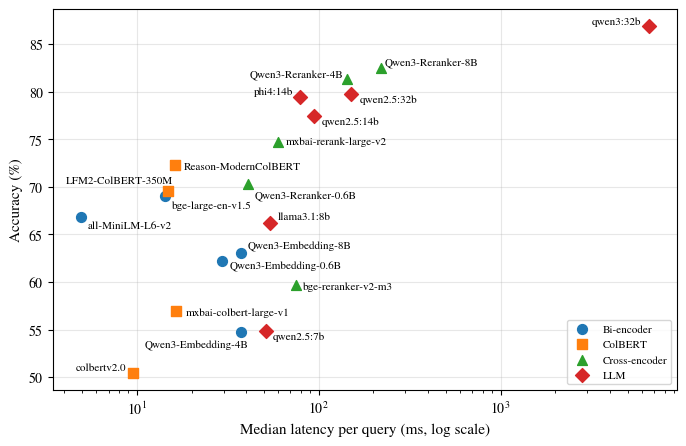

In [36]:
plt.rcParams.update({"font.family": "STIXGeneral", "mathtext.fontset": "stix", "pdf.fonttype": 42,
                     "font.size": 11, "axes.titlesize": 12, "axes.labelsize": 11,
                     "xtick.labelsize": 10, "ytick.labelsize": 10, "legend.fontsize": 10})

# 1. Prepare the data from table_cost
plot_df = table_cost.reset_index().rename(columns={
    "routing_method": "family",
    "Lat. K=14 (ms)": "latency",
    "Acc. K=14 (%)":  "accuracy",
})
plot_df["label"] = plot_df["model_name"].str.split("/").str[-1]

# 2. Same style as the recall scatter: (marker, colour, legend name)
style = {"bi-encoder": ("o", "tab:blue", "Bi-encoder"),
         "colbert": ("s", "tab:orange", "ColBERT"),
         "cross-encoder": ("^", "tab:green", "Cross-encoder"),
         "llm": ("D", "tab:red", "LLM")}

offsets = {
    # bi-encoders
    "all-MiniLM-L6-v2":              ( 5, -6, "left"),
    "bge-large-en-v1.5":             ( 5, -6, "left"),
    "Qwen3-Embedding-0.6B":          ( 6, -3, "left"), #left/right, up/down
    "Qwen3-Embedding-4B":            (5,  -9, "right"),
    "Qwen3-Embedding-8B":            ( 5,  5, "left"),
    # ColBERT
    "colbertv2.0":                   (-5,  4, "right"),
    "LFM2-ColBERT-350M":             (4,  8, "right"),
    "Reason-ModernColBERT":          ( 6,  -1, "left"),
    "mxbai-colbert-large-v1":        ( 7, -1, "left"),
    # cross-encoders
    "Qwen3-Reranker-0.6B":           ( 5, -9, "left"),
    "mxbai-rerank-large-v2":         ( 6, 1, "left"),
    "bge-reranker-v2-m3":            ( 5,  -1, "left"),
    "Qwen3-Reranker-4B":             (-2,  3, "right"),
    "Qwen3-Reranker-8B":             (3,  4, "left"),
    # LLMs
    "llama3.1:8b":                   ( 5,  5, "left"),
    "qwen2.5:7b":                    ( 5, -4, "left"),
    "phi4:14b":                      (-5,  4, "right"),
    "qwen2.5:14b":                   ( 6, -4, "left"),
    "qwen2.5:32b":                   ( 6, -4, "left"),
    "qwen3:32b":                     (-5,  4, "right"),
}

# 3. Plot
fig, ax = plt.subplots(figsize=(7, 4.6))

for fam, (marker, color, name) in style.items():
    s = plot_df[plot_df["family"] == fam]
    ax.scatter(s["latency"], s["accuracy"], marker=marker, color=color,
               s=50, label=name, zorder=3)

for _, r in plot_df.iterrows():
    if pd.isna(r["latency"]) or pd.isna(r["accuracy"]):    # LLMs: no K=14 data yet
        continue
    dx, dy, align = offsets.get(r["label"], (5, 3, "left"))
    ax.annotate(r["label"], (r["latency"], r["accuracy"]), xytext=(dx, dy),
                textcoords="offset points", ha=align, va="center", fontsize=8)

ax.set_xscale("log")
ax.set_xlabel("Median latency per query (ms, log scale)")
ax.set_ylabel("Accuracy (%)")
ax.grid(alpha=0.3)
ax.legend(loc="lower right", fontsize=8)

plt.tight_layout()
# plt.savefig("cost_scatter.pdf")
plt.show()